In [ ]:
"""
Brain Tumor Classification — Robust 3D CNN
==========================================
Data:
  Glioma     : LGG+HGG BraTS2019  240×240×155  t1ce  (limit 200)
  Meningioma : BraTS-MEN           240×240×155  t1c   (limit 200)
  Pituitary  : custom coronal      512×13×512   CECor (all 50)
  Healthy    : IXI                 variable     T1    (all 50)

Key design decisions:
  - ALL volumes → 96×96×96 with smart resize (no distortion for pituitary)
  - Pituitary: pad thin axis then center-crop, NOT stretch
  - Balanced training via WeightedRandomSampler
  - Class-weighted CrossEntropy
  - 3D ResNet with heavy dropout (0.6) for small classes
  - Mixup augmentation for better generalisation
  - Gradient checkpointing to save VRAM
"""

# ============================================================
# CELL 1 — Setup
# ============================================================
import os, random, json, warnings
import numpy as np
import nibabel as nib
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from pathlib import Path
from scipy.ndimage import zoom
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ── PATHS ──────────────────────────────────────────────────
PATHS = {
    "glioma":     Path("/home/23bq1a4293/Personal/project/seg_data/glioma/MICCAI_BraTS_2019_Data_Training"),
    "meningioma": Path("/home/23bq1a4293/Personal/project/seg_data/meningioma/BraTS-MEN-Train"),
    "pituitary":  Path("/home/23bq1a4293/Personal/project/seg_data/pitutary/pituitary_tumor_dataset"),
    "healthy":    Path("/home/23bq1a4293/Personal/project/seg_data/healthy"),
}

# Limits per class — keeps training manageable
LIMITS = {"glioma": 100, "meningioma": 100, "pituitary": 50, "healthy": 50}

SAVE_DIR     = Path("/home/23bq1a4293/Personal/project/models/Classification")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

LABEL_MAP    = {"glioma": 0, "meningioma": 1, "pituitary": 2, "healthy": 3}
LABEL_NAMES  = ["Glioma", "Meningioma", "Pituitary", "Healthy"]
LABEL_COLORS = ["#e74c3c", "#f39c12", "#3498db", "#2ecc71"]
VOL_SIZE     = (96, 96, 96)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(42); np.random.seed(42); torch.manual_seed(42)

print(f"✅ Device  : {device}")
print(f"   Classes : {LABEL_NAMES}")
print(f"   Vol size: {VOL_SIZE}")
print(f"   Limits  : {LIMITS}")


# ============================================================
# CELL 2 — Collect Files
# ============================================================
def get_all_files(tumor_type):
    path, files = PATHS[tumor_type], []

    if tumor_type == "glioma":
        for subfolder in ["LGG", "HGG"]:
            sp = path / subfolder
            if not sp.exists():
                continue
            for case in sorted(sp.iterdir()):
                if not case.is_dir():
                    continue
                # t1ce is most discriminative for glioma
                f = (next(case.glob("*t1ce.nii"), None) or
                     next(case.glob("*t1ce.nii.gz"), None) or
                     next(case.glob("*t1.nii"), None) or
                     next(case.glob("*t1.nii.gz"), None))
                if f:
                    files.append(f)

    elif tumor_type == "meningioma":
        for case in sorted(path.iterdir()):
            if not case.is_dir():
                continue
            f = (next(case.glob("*t1c.nii.gz"), None) or
                 next(case.glob("*t1n.nii.gz"), None) or
                 next(case.glob("*T1*.nii.gz"), None))
            if f:
                files.append(f)

    elif tumor_type == "pituitary":
        for sub in sorted(path.iterdir()):
            if not sub.is_dir() or not sub.name.startswith("sub-"):
                continue
            f = sub / "anat" / f"{sub.name}_acq-CECor_T1w.nii.gz"
            if f.exists():
                files.append(f)

    elif tumor_type == "healthy":
        files = sorted(path.glob("*.nii.gz"))

    # Apply limit with fixed random seed for reproducibility
    if len(files) > LIMITS[tumor_type]:
        rng = random.Random(42)
        files = rng.sample(files, LIMITS[tumor_type])

    return files


print("\nCollecting files...")
all_files, all_labels = [], []
class_counts = {}

for cls_name, label in LABEL_MAP.items():
    files = get_all_files(cls_name)
    all_files  += [str(f) for f in files]
    all_labels += [label] * len(files)
    class_counts[cls_name] = len(files)
    print(f"  {cls_name:<15}: {len(files):>4} files")

print(f"\n  Total: {len(all_files)} samples")
assert len(all_files) > 0, "No files found — check paths!"


# ============================================================
# CELL 3 — Class Weights (inverse frequency)
# ============================================================
counts   = np.array([class_counts[k]
                     for k in ["glioma","meningioma","pituitary","healthy"]],
                    dtype=np.float32)
total    = counts.sum()
inv_freq = total / (len(LABEL_NAMES) * counts)
inv_freq = inv_freq / inv_freq.sum() * len(LABEL_NAMES)

class_weights_tensor = torch.tensor(inv_freq, dtype=torch.float32).to(device)
label_to_weight      = {i: float(inv_freq[i]) for i in range(4)}

print("Class weights (inverse frequency):")
for name, w, c in zip(LABEL_NAMES, inv_freq, counts):
    print(f"  {name:<15}: weight={w:.3f}  (n={int(c)})")


# ============================================================
# CELL 4 — Stratified Train/Val Split
# ============================================================
X_train, X_val, y_train, y_val = train_test_split(
    all_files, all_labels,
    test_size=0.2, stratify=all_labels, random_state=42,
)
print(f"\nTrain: {len(X_train)} | Val: {len(X_val)}")
print(f"  Train: { {LABEL_NAMES[i]: y_train.count(i) for i in range(4)} }")
print(f"  Val  : { {LABEL_NAMES[i]: y_val.count(i)   for i in range(4)} }")


# ============================================================
# CELL 5 — Robust Volume Loading
# ============================================================
def load_volume(filepath, target=(96, 96, 96)):
    """
    Load any brain MRI NIfTI and return a uniform (96,96,96) float32 array.

    Handles:
      - Standard isotropic 240x240x155 (glioma/meningioma)
      - Thin coronal 512x13x512 (pituitary) — pad, don't stretch
      - Variable IXI healthy volumes
      - 4D multi-channel (take first channel)
    """
    arr = nib.load(str(filepath)).get_fdata(dtype=np.float32)

    # ── Handle 4D ──────────────────────────────────────────
    if arr.ndim == 4:
        # Take channel with most variance (most informative)
        variances = [arr[..., i].var() for i in range(arr.shape[-1])]
        arr = arr[..., int(np.argmax(variances))]

    # ── Ensure (D, H, W) with D = first axis ───────────────
    # Put the smallest dimension first (depth)
    if arr.ndim == 3:
        axes_order = np.argsort(arr.shape)        # ascending size
        if tuple(axes_order) != (0, 1, 2):
            arr = np.transpose(arr, axes_order)   # smallest → axis 0

    d, h, w = arr.shape

    # ── Clip intensity outliers ─────────────────────────────
    # Use non-zero voxels only (brain mask)
    nonzero = arr[arr > arr.min()]
    if len(nonzero) > 100:
        p1, p99 = np.percentile(nonzero, 1), np.percentile(nonzero, 99)
    else:
        p1, p99 = arr.min(), arr.max()
    arr = np.clip(arr, p1, p99)

    # ── Z-score normalization ───────────────────────────────
    mu    = arr.mean()
    sigma = arr.std() + 1e-8
    arr   = ((arr - mu) / sigma).astype(np.float32)

    # ── Smart resize strategy ───────────────────────────────
    td, th, tw = target

    if d < 30:
        # PITUITARY CASE: very thin depth (13-16 slices)
        # → resize H and W to target, then pad/repeat depth
        scale_h = th / h
        scale_w = tw / w
        arr = zoom(arr, (1.0, scale_h, scale_w), order=1)

        # Repeat slices along depth to reach target
        d_now = arr.shape[0]
        repeat = int(np.ceil(td / d_now))
        arr    = np.tile(arr, (repeat, 1, 1))[:td, :, :]

    else:
        # STANDARD CASE: isotropic or near-isotropic
        # Resize all axes proportionally
        factors = (td/d, th/h, tw/w)
        arr = zoom(arr, factors, order=1)

    # ── Final center crop + pad to exact target ─────────────
    def crop_or_pad(vol, target):
        result = np.zeros(target, dtype=np.float32)
        td, th, tw = target
        vd, vh, vw = vol.shape

        # Compute crop start (center-crop if too large)
        zs = max((vd - td) // 2, 0)
        ys = max((vh - th) // 2, 0)
        xs = max((vw - tw) // 2, 0)

        # Crop
        cropped = vol[zs:zs+td, ys:ys+th, xs:xs+tw]

        # Compute paste start (center-pad if too small)
        cz, cy, cx = cropped.shape
        pz = (td - cz) // 2
        py = (th - cy) // 2
        px = (tw - cx) // 2

        result[pz:pz+cz, py:py+cy, px:px+cx] = cropped
        return result

    arr = crop_or_pad(arr, target)

    assert arr.shape == target, f"Expected {target}, got {arr.shape}"
    return arr


# Quick test on one file per class
print("\nTesting volume loader...")
for cls_name in LABEL_MAP:
    files = get_all_files(cls_name)
    if files:
        try:
            vol = load_volume(files[0], VOL_SIZE)
            print(f"  {cls_name:<15}: OK — shape={vol.shape} "
                  f"min={vol.min():.2f} max={vol.max():.2f}")
        except Exception as e:
            print(f"  {cls_name:<15}: ❌ {e}")


# ============================================================
# CELL 6 — Dataset with Augmentation
# ============================================================
def mixup(vol1, lbl1, vol2, lbl2, alpha=0.2):
    """MixUp augmentation — blend two samples."""
    lam  = np.random.beta(alpha, alpha)
    vol  = lam * vol1 + (1 - lam) * vol2
    return vol, lbl1, lbl2, lam


class BrainDataset3D(Dataset):
    def __init__(self, filepaths, labels,
                 augment=False, vol_size=(96, 96, 96),
                 use_mixup=False):
        self.filepaths = filepaths
        self.labels    = labels
        self.augment   = augment
        self.vol_size  = vol_size
        self.use_mixup = use_mixup

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        try:
            vol = load_volume(self.filepaths[idx], self.vol_size)
        except Exception as e:
            print(f"⚠️  {Path(self.filepaths[idx]).name}: {e}")
            vol = np.zeros(self.vol_size, dtype=np.float32)

        vol   = torch.from_numpy(vol).float().unsqueeze(0)  # (1,D,H,W)
        label = self.labels[idx]

        if self.augment:
            vol = self._augment(vol)

        return vol, torch.tensor(label, dtype=torch.long)

    def _augment(self, vol):
    # Axis flips (D, H, W)
        for axis in [1, 2, 3]:
            if random.random() > 0.5:
                vol = torch.flip(vol, dims=[axis])

    # 90° rotation in axial plane (H, W)
        if random.random() > 0.5:
            vol = torch.rot90(vol, random.randint(1, 3), dims=[2, 3])

    # Intensity scaling
        if random.random() > 0.5:
            vol = vol * random.uniform(0.85, 1.15)

    # Intensity shift
        if random.random() > 0.5:
            vol = vol + random.uniform(-0.1, 0.1)

    # Gaussian noise
        if random.random() > 0.6:
            vol = vol + torch.randn_like(vol) * 0.02

    # Slice dropout (depth axis = 1)
        if random.random() > 0.7:
            d = vol.shape[1]
            n_drop = random.randint(1, max(1, d // 10))
            drop_idx = random.sample(range(d), n_drop)
            vol[:, drop_idx, :, :] = 0.0

        return torch.clamp(vol, -5.0, 5.0)


# WeightedRandomSampler for balanced mini-batches
train_sw = [label_to_weight[l] for l in y_train]
sampler  = WeightedRandomSampler(
    weights=train_sw,
    num_samples=len(y_train),
    replacement=True,
)

train_ds = BrainDataset3D(X_train, y_train, augment=True,
                          vol_size=VOL_SIZE, use_mixup=False)
val_ds   = BrainDataset3D(X_val,   y_val,   augment=False,
                          vol_size=VOL_SIZE)

train_loader = DataLoader(
    train_ds, batch_size=4, sampler=sampler,
    num_workers=2, pin_memory=True, drop_last=True,
)
val_loader = DataLoader(
    val_ds, batch_size=4, shuffle=False,
    num_workers=2, pin_memory=True,
)

print(f"\n✅ Train batches: {len(train_loader)} | Val batches: {len(val_loader)}")
vol, lbl = next(iter(train_loader))
print(f"   Batch shape: {vol.shape} | Labels: {lbl.tolist()}")


# ============================================================
# CELL 7 — 3D ResNet Model
# ============================================================
class ResBlock3D(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, dropout=0.0):
        super().__init__()
        self.conv1    = nn.Conv3d(in_ch, out_ch, 3,
                                  stride=stride, padding=1, bias=False)
        self.bn1      = nn.BatchNorm3d(out_ch)
        self.conv2    = nn.Conv3d(out_ch, out_ch, 3,
                                  padding=1, bias=False)
        self.bn2      = nn.BatchNorm3d(out_ch)
        self.relu     = nn.ReLU(inplace=True)
        self.dropout  = nn.Dropout3d(p=dropout) if dropout > 0 else nn.Identity()
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm3d(out_ch),
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.dropout(out)
        out = self.bn2(self.conv2(out))
        return self.relu(out + self.shortcut(x))


class BrainTumorCNN3D(nn.Module):
    """
    3D ResNet-18 style for 4-class brain tumor classification.

    Input : (B, 1, 96, 96, 96)
    Output: (B, 4)

    Architecture:
      Stem(32) → L1(64) → L2(128,↓2) → L3(256,↓2) → L4(512,↓2)
      → GAP → FC(256) → FC(64) → FC(4)
    """
    def __init__(self, in_channels=1, num_classes=4, dropout=0.5):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv3d(in_channels, 32, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(3, stride=2, padding=1),
        )

        block_dropout = dropout * 0.3  # lighter dropout inside blocks

        self.layer1 = nn.Sequential(
            ResBlock3D(32,  64,  stride=1, dropout=block_dropout),
            ResBlock3D(64,  64,  stride=1, dropout=block_dropout),
        )
        self.layer2 = nn.Sequential(
            ResBlock3D(64,  128, stride=2, dropout=block_dropout),
            ResBlock3D(128, 128, stride=1, dropout=block_dropout),
        )
        self.layer3 = nn.Sequential(
            ResBlock3D(128, 256, stride=2, dropout=block_dropout),
            ResBlock3D(256, 256, stride=1, dropout=block_dropout),
        )
        self.layer4 = nn.Sequential(
            ResBlock3D(256, 512, stride=2, dropout=block_dropout),
            ResBlock3D(512, 512, stride=1, dropout=block_dropout),
        )

        self.gap = nn.AdaptiveAvgPool3d(1)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout * 0.5),
            nn.Linear(64, num_classes),
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv3d):
                nn.init.kaiming_normal_(m.weight,
                                        mode='fan_out',
                                        nonlinearity='relu')
            elif isinstance(m, (nn.BatchNorm3d, nn.BatchNorm1d)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.gap(x)
        return self.classifier(x)


model = BrainTumorCNN3D(in_channels=1, num_classes=4, dropout=0.6).to(device)

total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\n✅ 3D ResNet")
print(f"   Total params    : {total:,}")
print(f"   Trainable params: {trainable:,}")

# Verify forward pass
with torch.no_grad():
    dummy = torch.randn(2, 1, *VOL_SIZE).to(device)
    out   = model(dummy)
    print(f"   Forward OK → output shape: {out.shape}")


# ============================================================
# CELL 8 — Loss, Optimizer, Scheduler
# ============================================================
from monai.losses import FocalLoss
criterion = FocalLoss(
    to_onehot_y=True,
    gamma=2.0,
    weight=class_weights_tensor
)

EPOCHS   = 80
patience = 20

optimizer = torch.optim.AdamW(
    model.parameters(), lr=3e-4, weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=3e-4,
    epochs=EPOCHS, steps_per_epoch=len(train_loader),
    pct_start=0.2,        # 20% warmup
    div_factor=10,        # start = max_lr/10
    final_div_factor=500, # end  = max_lr/5000
)

scaler = torch.cuda.amp.GradScaler()

print(f"✅ Loss    : CrossEntropy + label_smoothing=0.1 + class weights")
print(f"   Optim   : AdamW lr=3e-4 wd=1e-4")
print(f"   Sched   : OneCycleLR {EPOCHS} epochs + 20% warmup")
print(f"   Patience: {patience} epochs")




# ============================================================
# CELL 12 — Save Model Info
# ============================================================
model_info = {
    "model":         "3D ResNet (custom)",
    "num_classes":   4,
    "classes":       LABEL_NAMES,
    "vol_size":      list(VOL_SIZE),
    "in_channels":   1,
    "class_counts":  class_counts,
    "class_weights": {k: float(v) for k, v in zip(LABEL_NAMES, inv_freq)},
    "best_val_acc":  float(best_acc),
    "best_epoch":    best_epoch,
    "total_params":  total,
    "checkpoint":    str(SAVE_DIR / "best_model_3d.pth"),
    "limits":        LIMITS,
}
with open(SAVE_DIR / "model_info_3d.json", "w") as f:
    json.dump(model_info, f, indent=2)

print(f"\n✅ Checkpoint : {SAVE_DIR / 'best_model_3d.pth'}")
print(f"   Info file  : {SAVE_DIR / 'model_info_3d.json'}")
print(f"\n{json.dumps(model_info, indent=2)}")


/home/23bq1a4293/.local/lib/python3.11/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.0.7) or chardet (6.0.0.post1)/charset_normalizer (2.0.4) doesn't match a supported version!
  warnings.warn(


✅ Device  : cuda
   Classes : ['Glioma', 'Meningioma', 'Pituitary', 'Healthy']
   Vol size: (96, 96, 96)
   Limits  : {'glioma': 100, 'meningioma': 100, 'pituitary': 50, 'healthy': 50}

  glioma         :  100 files
  meningioma     :  100 files
  pituitary      :   50 files
  healthy        :   50 files

  Total: 300 samples
Class weights (inverse frequency):
  Glioma         : weight=0.667  (n=100)
  Meningioma     : weight=0.667  (n=100)
  Pituitary      : weight=1.333  (n=50)
  Healthy        : weight=1.333  (n=50)

Train: 240 | Val: 60
  Train: {'Glioma': 80, 'Meningioma': 80, 'Pituitary': 40, 'Healthy': 40}
  Val  : {'Glioma': 20, 'Meningioma': 20, 'Pituitary': 10, 'Healthy': 10}

Testing volume loader...
  glioma         : OK — shape=(96, 96, 96) min=-0.33 max=7.97
  meningioma     : OK — shape=(96, 96, 96) min=-0.36 max=6.34
  pituitary      : OK — shape=(96, 96, 96) min=-1.59 max=3.14
  healthy        : OK — shape=(96, 96, 96) min=-0.67 max=2.21

✅ Train batches: 60 | Val batc

NameError: name 'best_acc' is not defined

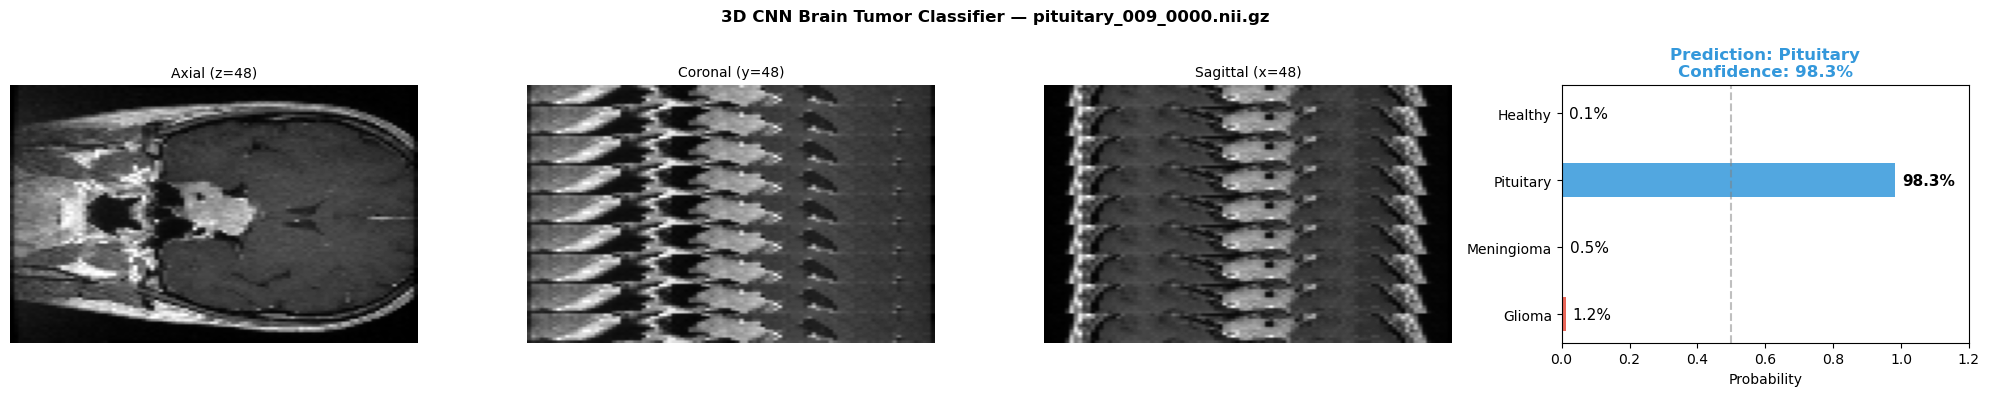


  File       : pituitary_009_0000.nii.gz
  Prediction : PITUITARY
  Confidence : 98.3%
  Probabilities:
    Glioma           1.2%  
    Meningioma       0.5%  
    Pituitary       98.3%  ████████████████████████ ← predicted
    Healthy          0.1%  


In [2]:
# ============================================================
# CELL 13 — Inference on Any NIfTI File
# ============================================================
def predict_tumor_3d(filepath, show=True):
    """
    Predict tumor type from any NIfTI file using the 3D CNN.
    Returns dict with tumor_type, confidence, probabilities.
    """
    # Load model
    clf  = BrainTumorCNN3D(in_channels=1, num_classes=4, dropout=0.5).to(device)
    ckpt = torch.load(str(SAVE_DIR / "best_model_3d.pth"),
                      map_location=device, weights_only=False)
    clf.load_state_dict(ckpt["model"])
    clf.eval()

    # Load volume
    try:
        vol = load_volume(str(filepath), VOL_SIZE)
    except Exception as e:
        print(f"❌ Load error: {e}")
        return None

    inp = torch.from_numpy(vol).float().unsqueeze(0).unsqueeze(0).to(device)

    with torch.no_grad():
        with torch.cuda.amp.autocast():
            out   = clf(inp)
        probs = F.softmax(out, dim=1).squeeze(0).cpu().numpy()
        pred  = int(probs.argmax())

    if show:
        fig, axes = plt.subplots(1, 4, figsize=(20, 4))
        mid = [s // 2 for s in VOL_SIZE]

        views = [
            (vol[mid[0], :, :], f"Axial (z={mid[0]})"),
            (vol[:, mid[1], :], f"Coronal (y={mid[1]})"),
            (vol[:, :, mid[2]], f"Sagittal (x={mid[2]})"),
        ]
        for ax, (sl, title) in zip(axes[:3], views):
            ax.imshow(sl, cmap='gray', origin='lower', aspect='auto')
            ax.set_title(title, fontsize=10)
            ax.axis('off')

        bars = axes[3].barh(LABEL_NAMES, probs,
                            color=LABEL_COLORS, alpha=0.85, height=0.5)
        axes[3].set_xlim(0, 1.2)
        axes[3].axvline(0.5, color='gray', linestyle='--', alpha=0.5)
        for bar, p in zip(bars, probs):
            axes[3].text(
                bar.get_width() + 0.02,
                bar.get_y() + bar.get_height() / 2,
                f'{p:.1%}', va='center', fontsize=11,
                fontweight='bold' if p == probs.max() else 'normal',
            )
        axes[3].set_title(
            f"Prediction: {LABEL_NAMES[pred]}\n"
            f"Confidence: {probs[pred]:.1%}",
            fontsize=12, fontweight='bold',
            color=LABEL_COLORS[pred],
        )
        axes[3].set_xlabel("Probability")
        plt.suptitle(f"3D CNN Brain Tumor Classifier — {Path(filepath).name}",
                     fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.show()

    print(f"\n{'='*55}")
    print(f"  File       : {Path(filepath).name}")
    print(f"  Prediction : {LABEL_NAMES[pred].upper()}")
    print(f"  Confidence : {probs[pred]:.1%}")
    print(f"  Probabilities:")
    for name, p, col in zip(LABEL_NAMES, probs, LABEL_COLORS):
        bar  = "█" * int(p * 25)
        mark = " ← predicted" if name == LABEL_NAMES[pred] else ""
        print(f"    {name:<15} {p:>5.1%}  {bar}{mark}")
    print(f"{'='*55}")

    seg_map = {"Glioma": "glioma", "Meningioma": "meningioma",
               "Pituitary": "pituitary", "Healthy": "none"}

    return {
        "tumor_type":        LABEL_NAMES[pred],
        "label":             pred,
        "confidence":        float(probs[pred]),
        "probabilities":     dict(zip(LABEL_NAMES, probs.tolist())),
        "recommended_model": seg_map[LABEL_NAMES[pred]],
    }


# ── Test on pituitary patient ───────────────────────────────
result = predict_tumor_3d(
    "/home/23bq1a4293/Personal/project/nnunet/nnUNet_raw/"
    "Dataset001_Pituitary/imagesTr/pituitary_009_0000.nii.gz"
)

In [3]:
from pathlib import Path

# ============================================================
# Load model ONCE (outside function)
# ============================================================
def load_classifier():
    clf = BrainTumorCNN3D(in_channels=1, num_classes=4, dropout=0.5).to(device)
    ckpt = torch.load(str(SAVE_DIR / "best_model_3d.pth"),
                      map_location=device, weights_only=False)
    clf.load_state_dict(ckpt["model"])
    clf.eval()
    return clf

model_clf = load_classifier()


# ============================================================
# Predict ALL NIfTI files in a patient folder
# ============================================================
def predict_patient_folder(folder_path, show=False):
    folder = Path(folder_path)

    if not folder.exists():
        print("❌ Folder not found")
        return None

    # Get all nifti files EXCEPT segmentation
    nifti_files = [
        f for f in folder.rglob("*")
        if (f.suffix in [".nii", ".gz"] and "seg" not in f.name.lower())
    ]

    if len(nifti_files) == 0:
        print("❌ No valid NIfTI files found")
        return None

    results = []

    print(f"\n📁 Patient folder: {folder.name}")
    print(f"🔍 Found {len(nifti_files)} NIfTI files (excluding seg)\n")

    for filepath in nifti_files:
        try:
            vol = load_volume(str(filepath), VOL_SIZE)
        except Exception as e:
            print(f"❌ Skipping {filepath.name} (error)")
            continue

        inp = torch.from_numpy(vol).float().unsqueeze(0).unsqueeze(0).to(device)

        with torch.no_grad():
            with torch.cuda.amp.autocast():
                out = model_clf(inp)

            probs = F.softmax(out, dim=1).squeeze(0).cpu().numpy()
            pred  = int(probs.argmax())

        result = {
            "file": str(filepath.name),
            "tumor_type": LABEL_NAMES[pred],
            "confidence": float(probs[pred]),
            "probabilities": dict(zip(LABEL_NAMES, probs.tolist()))
        }

        results.append(result)

        # Print summary
        print(f"{filepath.name:<35} → {LABEL_NAMES[pred]:<12} ({probs[pred]:.1%})")

        # Optional visualization
        if show:
            predict_tumor_3d(filepath, show=True)

    # ========================================================
    # Final patient-level prediction (majority voting)
    # ========================================================
    votes = [r["tumor_type"] for r in results]
    final_pred = max(set(votes), key=votes.count)

    print(f"\n{'='*60}")
    print(f"🧠 FINAL PATIENT PREDICTION: {final_pred}")
    print(f"{'='*60}")

    return {
        "patient": folder.name,
        "final_prediction": final_pred,
        "files": results
    }

In [13]:
predict_patient_folder(
    "/home/23bq1a4293/Personal/project/seg_data/meningioma/BraTS-MEN-Train/BraTS-MEN-00018-000",
    show=False
)


📁 Patient folder: BraTS-MEN-00018-000
🔍 Found 4 NIfTI files (excluding seg)

BraTS-MEN-00018-000-t1c.nii.gz      → Glioma       (42.1%)
BraTS-MEN-00018-000-t2w.nii.gz      → Meningioma   (48.3%)
BraTS-MEN-00018-000-t1n.nii.gz      → Glioma       (42.2%)
BraTS-MEN-00018-000-t2f.nii.gz      → Glioma       (41.2%)

🧠 FINAL PATIENT PREDICTION: Glioma


{'patient': 'BraTS-MEN-00018-000',
 'final_prediction': 'Glioma',
 'files': [{'file': 'BraTS-MEN-00018-000-t1c.nii.gz',
   'tumor_type': 'Glioma',
   'confidence': 0.421142578125,
   'probabilities': {'Glioma': 0.421142578125,
    'Meningioma': 0.39306640625,
    'Pituitary': 0.07177734375,
    'Healthy': 0.114013671875}},
  {'file': 'BraTS-MEN-00018-000-t2w.nii.gz',
   'tumor_type': 'Meningioma',
   'confidence': 0.483154296875,
   'probabilities': {'Glioma': 0.422119140625,
    'Meningioma': 0.483154296875,
    'Pituitary': 0.034942626953125,
    'Healthy': 0.05987548828125}},
  {'file': 'BraTS-MEN-00018-000-t1n.nii.gz',
   'tumor_type': 'Glioma',
   'confidence': 0.421875,
   'probabilities': {'Glioma': 0.421875,
    'Meningioma': 0.392578125,
    'Pituitary': 0.06317138671875,
    'Healthy': 0.1221923828125}},
  {'file': 'BraTS-MEN-00018-000-t2f.nii.gz',
   'tumor_type': 'Glioma',
   'confidence': 0.41162109375,
   'probabilities': {'Glioma': 0.41162109375,
    'Meningioma': 0.4084